# 用 SymPy 做符号运算

SymPy 是 Python 的符号计算库，能把式子按符号原样变形，也能做微分、积分和解方程。与专门的符号计算软件相比，它的功能和速度都差一些，但全部用 Python 写成，因此可以和 NumPy、SciPy 配合使用。

这一章按下面的顺序说明。

- 通过例子把握使用 SymPy 的流程
- 理解式子的结构(符号、数值、运算符、通配符)
- 计算式子的变形、方程、微分、微分方程与积分

最后一节还会说明，怎样把符号求出的式子转换成数值计算的函数、再交给 SciPy 使用。

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import helper.matplotlib
import helper.magics
from sympy import *
import sympy

sympy.__version__

'1.14.0'

## 从例子开始

在讲语法之前，先用几个例子看看用 SymPy 解题的流程。

### 封面上的公式

这是本书封面上的公式。

$$e^{\mathrm{i} \pi} + 1 = 0$$

它称为欧拉恒等式：$e$ 是自然对数的底、$\mathrm{i}$ 是虚数单位、$\pi$ 是圆周率，式子用加法、乘法和幂把这 5 个基本常数连在一起。下面用 SymPy 确认一下。

`E` 是自然对数的底、`I` 是虚数单位、`pi` 是圆周率，所以直接算就行。

In [2]:
from sympy import *

E ** (I * pi) + 1

0

SymPy 也能帮助式子变形与证明。把 $\pi$ 代入下面的欧拉公式，就得到欧拉恒等式。

$$e^{{\mathrm{i}}x}=\cos x+ {\mathrm{i}} \sin x$$

用 `expand()` 可以展开式子，这里试着展开 $e^{{\mathrm{i}}x}$。

In [3]:
x = symbols("x")
expand(E ** (I * x))

exp(I*x)

这样展开不出来，把 `complex=True` 传进去，式子就会分成实部与虚部。

In [4]:
expand(exp(I * x), complex=True)

I*exp(-im(x))*sin(re(x)) + exp(-im(x))*cos(re(x))

虽然展开了，但结果很复杂：$\operatorname{re}()$ 取实部、$\operatorname{im}()$ 取虚部，而 `expand()` 把 $x$ 当成复数处理，所以才成了这个样子，把 $x$ 设为实数就简单了。

In [5]:
x = Symbol("x", real=True)  # 把 x 设为实数
expand(exp(I * x), complex=True)

I*sin(x) + cos(x)

欧拉公式出来了，要证明它得用泰勒展开。

In [6]:
tmp = series(exp(I * x), x, 0, 10)  # 把 e^{ix} 展开到 10 项
tmp

1 + I*x - x**2/2 - I*x**3/6 + x**4/24 + I*x**5/120 - x**6/720 - I*x**7/5040 + x**8/40320 + I*x**9/362880 + O(x**10)

展开之后，虚数项与实数项交替出现。按欧拉公式，虚数项之和应当等于 $\sin{x}$ 的泰勒级数、实数项之和应当等于 $\cos{x}$ 的泰勒展开，所以先取 `tmp` 的实部。

In [7]:
re(tmp)

x**8/40320 - x**6/720 + x**4/24 - x**2/2 + re(O(x**10)) + 1

把 $\cos{x}$ 做泰勒展开，确认各项与上面的结果一致。

In [8]:
series(cos(x), x, 0, 10)

1 - x**2/2 + x**4/24 - x**6/720 + x**8/40320 + O(x**10)

再取 `tmp` 的虚部。

In [9]:
im(tmp)

x**9/362880 - x**7/5040 + x**5/120 - x**3/6 + x + im(O(x**10))

把 $\sin{x}$ 做泰勒展开，同样确认两者一致。

In [10]:
series(sin(x), x, 0, 10)

x - x**3/6 + x**5/120 - x**7/5040 + x**9/362880 + O(x**10)

$e^{{\mathrm{i}}x}$ 的实部与 $\cos{x}$、虚部与 $\sin{x}$ 都对上了，欧拉公式由此得到确认。

### 球的体积

讲 SciPy 的那一章用数值积分求过球的体积，而 SymPy 的 `integrate()` 能算符号积分，先看不定积分。

In [11]:
integrate(x * sin(x), x)

-x*cos(x) + sin(x)

把积分范围作为参数传进去，算的就是定积分。

In [12]:
integrate(x * sin(x), (x, 0, 2 * pi))

-2*pi

要求球的体积，先算出圆的面积。半径为 `r` 的圆，上半部分可以用下面的函数表示。

$$y(x) = \sqrt{r^2 - x^2}$$

把它从 $-r$ 积到 $r$ 得到半圆的面积，再乘 2 就是圆的面积。

`symbols()` 能一次做出多个符号；半径 `r` 是正数，所以加上 `positive=True`。

In [13]:
x, y = symbols("x, y")  # 准备符号
r = symbols("r", positive=True)  # 半径是正数
circle_area = 2 * integrate(sqrt(r**2 - x**2), (x, -r, r))  # 半圆乘 2 得到圆面积
circle_area

pi*r**2

把这个面积的式子再积分，就得到球的体积，不过截面上圆的半径会随 x 的位置而变：截面半径就是 $y(x)$，所以把 `circle_area` 里的 `r` 换成 $\sqrt{r^2 - x^2}$。

In [14]:
circle_area = circle_area.subs(r, sqrt(r**2 - x**2))
circle_area

pi*(r**2 - x**2)

把这个式子从 $-r$ 积到 $r$，就得到球的体积公式。

In [15]:
integrate(circle_area, (x, -r, r))

4*pi*r**3/3

`subs()` 用来替换式子里的符号，调用方式有三种。

* `expression.subs(x, y)`：把 `x` 换成 `y`。
* `expression.subs({x: y, u: v})`：用字典做多处替换。
* `expression.subs([(x, y), (u, v)])`：用列表做多处替换。

多处替换是按顺序进行的，所以 `expression.subs([(x, y), (y, x)])` 并不能把 `x` 与 `y` 互换。

### 数值微分

数值微分是由离散点上的函数值近似导数值的方法：只要 $h$ 足够接近 0，就可以用下面的式子近似 $f(x)$ 的导数。

$$f'(x)\approx \frac {f(x+h)-f(x)}{h}$$

由于只用到两个点上的值，所以叫两点公式；用到的点越多，精度越高。在 SymPy 里，对导数的式子调用 `as_finite_difference()` 就能自动做出 N 点公式。

要把 `f` 变成表示数学函数的符号，得加上 `cls=Function`；`h` 是正数。

In [16]:
x = symbols("x", real=True)  # 把 x 设为实数
h = symbols("h", positive=True)  # 步长
f = symbols("f", cls=Function)  # 表示函数的符号

`f(x)` 是以 `x` 为变量的函数，用 `diff()` 对 $x$ 求一阶导数。

In [17]:
f_diff = f(x).diff(x, 1)  # 1 階導関数
f_diff

Derivative(f(x), x)

再用 `as_finite_difference()` 把一阶导数变成使用 `f(x)`、`f(x-h)`、`f(x-2*h)`、`f(x-3*h)` 的四点公式。

In [18]:
expr_diff = f_diff.as_finite_difference([x, x - h, x - 2 * h, x - 3 * h])
expr_diff

11*f(x)/(6*h) - f(-3*h + x)/(3*h) + 3*f(-2*h + x)/(2*h) - 3*f(-h + x)/h

以 $f(x)=x \cdot e^{-x^2}$ 为例，比较数值微分与符号微分的误差：先用 `subs()` 把 `f(x)` 换成目标函数，再用 `doit()` 算出微分。

In [19]:
sym_dexpr = f_diff.subs(f(x), x * exp(-(x**2))).doit()  # 記号微分
sym_dexpr

-2*x**2*exp(-x**2) + exp(-x**2)

用 `lambdify()` 把这个式子变成数值计算的函数，第 1 个参数是变量的列表、第 2 个参数是式子；由于取 `modules="numpy"`，数组可以直接传进去。

In [20]:
sym_dfunc = lambdify([x], sym_dexpr, modules="numpy")
sym_dfunc(np.array([-1, 0, 1]))

array([-0.36787944,  1.        , -0.36787944])

`expr_diff` 是加法式子，所以能用 `args` 把各项取出来。

In [21]:
print(expr_diff.args)

(-3*f(-h + x)/h, -f(-3*h + x)/(3*h), 3*f(-2*h + x)/(2*h), 11*f(x)/(6*h))


各项并没有按变量由小到大排列。这里用通配符 `w` 与 `c` 做出模板 `c * f(w)`，套到各项上，取出系数与函数的参数。

In [22]:
w = Wild("w")
c = Wild("c")
patterns = [arg.match(c * f(w)) for arg in expr_diff.args]

匹配的结果是以通配符为键的字典：下面的输出是第一项的结果，可以看出系数是 `-3 / h`、`f` 的参数是 `-h + x`。

In [23]:
print(patterns[0])  # 第一项的匹配结果

{w_: -h + x, c_: -3/h}


按通配符 `w` 的值排序，再把 `c` 的值排起来，就得到变量由小到大的系数。

In [24]:
coefficients = [t[c] for t in sorted(patterns, key=lambda t: t[w])]
print(coefficients)

[-1/(3*h), 3/(2*h), -3/h, 11/(6*h)]


把系数式子里的 `h` 换成 `0.001`，做出系数的数组；由于 SymPy 的计算结果是 `Float`，所以用 `float()` 转成 Python 的浮点数。

In [25]:
coeff_arr = np.array([float(coeff.subs(h, 1e-3)) for coeff in coefficients])
print(coeff_arr)

[ -333.33333333  1500.         -3000.          1833.33333333]


用 NumPy 算数值微分，再与 `sym_dfunc()` 的值比较，求出最大误差。

In [26]:
def moving_window(x, size):
    from numpy.lib.stride_tricks import as_strided

    x = np.ascontiguousarray(x)
    return as_strided(
        x, shape=(x.shape[0] - size + 1, size), strides=(x.itemsize, x.itemsize)
    )


x_arr = np.arange(-2, 2, 1e-3)  # 用于求值的点
y_arr = x_arr * np.exp(-x_arr * x_arr)
num_res = (moving_window(y_arr, 4) * coeff_arr).sum(axis=1)  # 用四点公式做数值微分
sym_res = sym_dfunc(x_arr[3:])  # 符号微分的值
print(np.max(abs(num_res - sym_res)))

4.089441674182126e-09


为了看清点数与误差的关系，下面的 `finite_diff_coefficients()` 计算 2、3、4 点公式的系数并画出误差，纵轴是对数刻度。

In [27]:
def finite_diff_coefficients(f_diff, order, h):
    """求 order 点公式的系数。"""
    v = f_diff.variables[0]
    points = [x - i * h for i in range(order)]
    expr_diff = f_diff.as_finite_difference(points)
    w = Wild("w")
    c = Wild("c")
    patterns = [arg.match(c * f(w)) for arg in expr_diff.args]
    coefficients = np.array([float(t[c]) for t in sorted(patterns, key=lambda t: t[w])])
    return coefficients

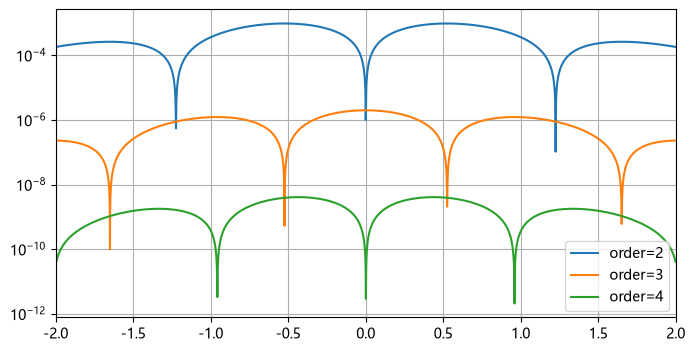

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
for order in [2, 3, 4]:
    coeff_arr = finite_diff_coefficients(f_diff, order, 0.001)

    x_arr = np.arange(-2, 2, 1e-3)
    y_arr = x_arr * np.exp(-x_arr * x_arr)
    num_res = (moving_window(y_arr, order) * coeff_arr).sum(axis=1)
    sym_res = sym_dfunc(x_arr[order - 1 :])
    error = np.abs(num_res - sym_res)
    ax.semilogy(x_arr[order - 1 :], error, label=f"order={order}")

ax.grid(True)
ax.set_xlim(-2, 2)
ax.legend(loc="lower right");

## 式子的结构

这一节看 SymPy 的式子由哪些部件构成。内容读起来可能枯燥，但理清结构之后，复杂的计算也能驾驭。

### 符号

数学符号用 `Symbol` 对象表示，`name` 属性是符号的名字，显示式子时会用到它。符号的名字与 Python 的变量名没有关系，不过一般让它们一致，这样读代码时不必来回对照。

想一次做出与符号同名的一批变量时，用 `var()` 很方便。

In [29]:
var("x0 y0 x1 y1")

(x0, y0, x1, y1)

这段代码做出 `x0`、`y0`、`x1`、`y1` 四个 `Symbol`，并放进同名的变量里；把 `Symbol` 转成字符串就得到 `name`，所以显示变量 `x0` 时看到的就是 `x0`。

In [30]:
%C type(x0); x0.name; type(x0.name)

        type(x0)          x0.name  type(x0.name)
------------------------  -------  -------------
sympy.core.symbol.Symbol  'x0'     str          


在交互环境里用 `var()` 很方便，但在程序里用会让人看不明白，那种场合就用 `symbols()` 造出来再赋值给变量。

In [31]:
x1, y1 = symbols("x1 y1")
type(x1)

sympy.core.symbol.Symbol

也可以绕过 `symbols()`，直接使用 `Symbol` 类。

In [32]:
x2 = Symbol("x2")

变量名与符号的名字不一致也没关系：下面的例子里用变量 `t` 表示符号 `x0`，用变量 `a`、`b` 表示符号 `alpha`、`beta`，而用希腊字母的名字造出来的符号，显示时也是希腊字母。

In [33]:
t = x0
a, b = symbols("alpha, beta")  # 希腊字母的符号
sin(a) + sin(b) + x0

x0 + sin(alpha) + sin(beta)

式子的符号通常带有前提假设，比如 `m`、`n` 是整数、`z` 是复数。`var()`、`symbols()`、`Symbol()` 都能用关键字参数指定前提，而前提会影响计算的结果：下面的例子做出整数的 `m`、`n` 与正数 `x`。

In [34]:
m, n = symbols("m, n", integer=True)  # 整数的符号
x = Symbol("x", positive=True)

每个符号都有很多 `is_*` 属性用来查前提，在交互环境里可以用补全看名字：下划线之后是大写的属性表示对象的种类，全是小写的属性则表示前提。

In [35]:
%omit [attr for attr in dir(x) if attr.startswith("is_") and attr.lower() == attr]

['is_algebraic',
 'is_algebraic_expr',
 'is_antihermitian',
 'is_commutative',
...


下面的结果说明 `x` 是符号，而且是正数(可以比较、也不是虚数)；此外 `x` 也是复数，因为复数包含实数、实数包含正数。

In [36]:
%C x.is_Symbol; x.is_positive; x.is_imaginary; x.is_complex

x.is_Symbol  x.is_positive  x.is_imaginary  x.is_complex
-----------  -------------  --------------  ------------
True         True           False           True        


用 `assumptions0` 能一次看到所有前提：`commutative` 为 `True` 就表示这个符号满足交换律，其余前提从名字就能明白意思，这里不再解释。

In [37]:
%col 4 x.assumptions0

{'commutative': True,              'complex': True,                  'extended_negative': False,       'extended_nonnegative': True,    
 'extended_nonpositive': False,    'extended_nonzero': True,         'extended_positive': True,        'extended_real': True,           
 'finite': True,                   'hermitian': True,                'imaginary': False,               'infinite': False,               
 'negative': False,                'nonnegative': True,              'nonpositive': False,             'nonzero': True,                 
 'positive': True,                 'real': True,                     'zero': False}                   


SymPy 的对象全部派生自 `Basic` 类，`is_*` 与 `assumptions0` 也定义在 `Basic` 上。

In [38]:
Symbol.mro()

[sympy.core.symbol.Symbol,
 sympy.core.expr.AtomicExpr,
 sympy.core.basic.Atom,
 sympy.core.expr.Expr,
 sympy.logic.boolalg.Boolean,
 sympy.core.basic.Basic,
 sympy.printing.defaults.Printable,
 sympy.core.evalf.EvalfMixin,
 object]

### 数值

为了做符号计算，SymPy 有自己的一套数值体系，所以 SymPy 的数值与 Python 的 `int`、`float` 是不同的对象。这样做是为了让 `1/3` 保持为分数，而不是变成 `0.333…`；为了方便，Python 的数值会自动转换成 SymPy 的数值，也可以用 `S` 显式转换。计算里一旦有 SymPy 的数值，结果也就是 SymPy 的数值。

In [39]:
%C 1/2 + 1/3; S(1)/2 + 1/S(3)

    1/2 + 1/3       S(1)/2 + 1/S(3)
------------------  ---------------
0.8333333333333333  5/6            


`5/6` 是 `Rational` 对象，表示两个整数之商，对应数学里的有理数；也可以用 `Rational` 直接构造。

In [40]:
print(type(S(5) / 6))
Rational(5, 10)  # 有理数会自动约分

<class 'sympy.core.numbers.Rational'>


1/2

实数用 `Float` 对象表示，它与普通的浮点数相似，但能指定有效数字的位数。`float` 与 `Float` 内部都是二进制，所以都表示不了精确的十进制小数，用 `N()` 可以看到实际的值。

下面的代码把 `0.1` 与 `10000.1` 按 60 位显示，可以看出值越大、绝对精度越低。

In [41]:
print(N(0.1, 60))
print(N(10000.1, 60))

0.100000000000000005551115123125782702118158340454101562500000
10000.1000000000003637978807091712951660156250000000000000000


`float` 的精度是固定的，所以构造 `Float` 时即使指定了位数，误差也不会减少；那种情况下要把数值以字符串形式传进去。

In [42]:
print(
    N(Float(0.1, 60), 60)
)  # 用浮点数构造 Real 对象时，精度与浮点数相同
print(
    N(Float("0.1", 60), 60)
)  # 用字符串构造 Real 对象时，指定的精度才有效
print(N(Float("0.1", 60), 65))  # 提高显示精度就能看出它并不完全精确

0.100000000000000005551115123125782702118158340454101562500000
0.100000000000000000000000000000000000000000000000000000000000
0.099999999999999999999999999999999999999999999999999999999999996111


`N()` 把式子变成指定有效位数的 `Float`，这里把 $\pi$ 与 $\sqrt{2}$ 算到 50 位。

In [43]:
print(N(pi, 50))
print(N(sqrt(2), 50))

3.1415926535897932384626433832795028841971693993751
1.4142135623730950488016887242096980785696718753769


### 运算符与函数

SymPy 把数学的运算符与函数全都自己定义了一遍：`Add` 是加法、`Mul` 是乘法、`Pow` 是幂、`sin` 是正弦函数，和 `Symbol` 一样都派生自 `Basic`。在交互环境里看 `Add.mro()` 之类，就能知道派生关系。

用这些类可以造出复杂的式子。

In [44]:
var("x y z n")
Add(x, y, z)

x + y + z

In [45]:
Add(Mul(x, y, z), Pow(x, y), sin(z))

x*y*z + x**y + sin(z)

`Basic` 上定义了 `__add__()` 这类特殊方法，所以能用写 Python 表达式的方式造出 SymPy 的式子。

In [46]:
x * y * z + x**y + sin(z)

x*y*z + x**y + sin(z)

`Basic` 有两个重要属性：`func` 与 `args`，其中 `func` 是对象的类、`args` 是它的参数，由此可以观察 SymPy 造出来的式子。

减法没有对应的类，下面看看减法是怎么表示的。

In [47]:
t = x - y
%C t.func; t.args; t.args[1].func; t.args[1].args

      t.func         t.args    t.args[1].func    t.args[1].args
------------------  -------  ------------------  --------------
sympy.core.add.Add  (x, -y)  sympy.core.mul.Mul  (-1, y)       


`x - y` 会变成 `Add(x, Mul(-1, y))`。除法同样没有对应的类，`x / y` 是怎样表示的，不妨照着查一下。

SymPy 的式子是 `Basic` 对象嵌套成的树，用 `dotprint()` 能把式子变成 Graphviz 的 DOT 语言图，再用本书的 `%dot` 命令显示在 Notebook 里。下图是式子 $x y \frac{\sqrt{x^{2} - y^{2}}}{x + y}$ 的结构。

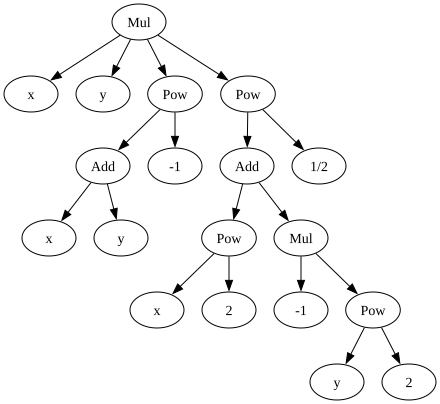

In [48]:
from sympy.printing.dot import dotprint

graph = dotprint(x * y * sqrt(x**2 - y**2) / (x + y))

import graphviz

graphviz.Source(graph, format="svg")

`args` 是元组，所以式子造好之后不能修改；不可修改也有好处，例如式子可以当作字典的键。

除了 SymPy 准备好的数学函数，也可以用 `Function()` 做出自己用的函数符号。

In [49]:
f = Function("f")

`Function` 是类，但这里得到的 `f` 并不是 `Function` 的实例：与 `sin` 一样，`f` 是派生自 `Function` 的类。

In [50]:
issubclass(f, Function)

True

用 `f` 造式子，就得到它的实例。

In [51]:
t = f(x, y)
%C type(t); t.func; t.args

type(t)  t.func  t.args
-------  ------  ------
f        f       (x, y)


`f` 的实例 `t` 可以用于式子的计算。

In [52]:
t + t * t

f(x, y)**2 + f(x, y)

用 `symbols()` 或 `var()` 时加上 `cls=Function`，同样能做出函数的符号。

In [53]:
g, h = symbols("g h", cls=Function)
g(x, y) + h(y) ** 2

g(x, y) + h(y)**2

运算符与函数一般会自动计算，传入 `evaluate=False` 就不会自动算了：`x + 2*x` 会变成 `3*x`，而给 `Add` 传 `evaluate=False` 时，它保持原样。

In [54]:
Add(x, 2 * x, evaluate=False)

x + 2*x

也有一些式子从一开始就不计算：`Integral` 表示积分式，它不做积分，而是带着积分符号原样显示。

In [55]:
Integral(sin(x))

Integral(sin(x), x)

要计算积分，可以用 `integrate()`，或者调用式子的 `doit()`。

In [56]:
from IPython.display import display_latex

display_latex(integrate(sin(x), x))
display_latex(Integral(sin(x), x).doit())

当 SymPy 算不出积分时，`integrate()` 会把积分式原样返回。

In [57]:
integrate(x**x, x)

Integral(x**x, x)

很多运算都配有一对：做计算的函数与表示式子的类。`diff()` 是做微分的函数、`Derivative` 是微分的式子；`laplace_transform()` 是做拉普拉斯变换的函数，`LaplaceTransform` 就是它的式子。

### 通配符

用通配符可以做出套用到式子上的模板：下面例子里的 `a` 与 `b` 是 `Wild` 对象，`a * b ** 2` 就是模板。把模板传给式子的 `match()`，就能检查是否能对上，返回值是以通配符为键、对上的子式为值的字典。

:::{tip}
执行 `init_printing()` 之后，计算结果会用数学符号显示，不过 Python 的内置对象也会变成 LaTeX 显示；本书里内置对象仍用普通文字显示，需要 LaTeX 时用 `%latex` 魔法命令。
:::

In [58]:
x, y = symbols("x, y")  # 准备符号
a = Wild("a")
b = Wild("b")
%latex (3 * x * (x + y)**2).match(a * b**2)

`find()` 在式子的树里找出所有符合模板的子树，下面的代码从 $(x + y)^3$ 的展开式里找。

In [59]:
expr = expand((x + y) ** 3)
%latex expr
%latex expr.find(a * b**2)

整数 2 也能对上，多少有些意外；用 `find_match()` 把各个子式与模板的匹配结果列成表，就能看清原因。

In [60]:
from helper.html import latex_table

def find_match(expr, pattern):
    return [e.match(pattern) for e in expr.find(pattern)]


def display_match_table(expr, pattern):
    sub_exprs = expr.find(pattern)
    rows = [
        (f"{latex(sub_expr)}", f"{latex(sub_expr.match(pattern))}")
        for sub_expr in sub_exprs
    ]
    columns = ["式子", "匹配结果"]
    return latex_table(rows, columns, columns)

find_match(expr, a * b**2)
display_match_table(expr, a * b**2)

式子,匹配结果
\[3 x y^{2}\],"\[\left\{ a : 3 x, \ b : y\right\}\]"
\[2\],"\[\left\{ a : 1, \ b : \sqrt{2}\right\}\]"
\[3\],"\[\left\{ a : 1, \ b : \sqrt{3}\right\}\]"
\[y^{3}\],"\[\left\{ a : 1, \ b : y^{\frac{3}{2}}\right\}\]"
\[x^{3} + 3 x^{2} y + 3 x y^{2} + y^{3}\],"\[\left\{ a : 1, \ b : \sqrt{x^{3} + 3 x^{2} y + 3 x y^{2} + y^{3}}\right\}\]"
\[x^{3}\],"\[\left\{ a : 1, \ b : x^{\frac{3}{2}}\right\}\]"
\[y\],"\[\left\{ a : 1, \ b : \sqrt{y}\right\}\]"
\[x^{2}\],"\[\left\{ a : 1, \ b : x\right\}\]"
\[y^{2}\],"\[\left\{ a : 1, \ b : y\right\}\]"
\[3 x^{2} y\],"\[\left\{ a : 3 y, \ b : x\right\}\]"


从结果可以看出，SymPy 是在变形式子的同时寻找数学上正确的匹配。想避开这种变形，就在造通配符时用 `exclude` 指定不希望套上的对象，只要对上的式子里含有该对象就不匹配。

下面的 `a` 与 `b` 都不含 1，而 `b` 还不含幂——要注意 SymPy 里平方根是用幂表示的。

In [61]:
a = Wild("a", exclude=[1])
b = Wild("b", exclude=[1, Pow])

find_match(expr, a * b**2)
display_match_table(expr, a * b**2)

式子,匹配结果
\[x^{3}\],"\[\left\{ a : x, \ b : x\right\}\]"
\[3 x^{2} y\],"\[\left\{ a : 3 y, \ b : x\right\}\]"
\[y^{3}\],"\[\left\{ a : y, \ b : y\right\}\]"
\[3 x y^{2}\],"\[\left\{ a : 3 x, \ b : y\right\}\]"


用 `replace()` 可以替换式子里的子式：下面的例子把符合 `a * b**2` 的子式换成 `(a + b)**2`。

In [62]:
expr.replace(a * b**2, (a + b) ** 2)

4*x**2 + 4*y**2 + (x + 3*y)**2 + (3*x + y)**2

`WildFunction` 是能匹配任意函数的通配符：下面例子里的 `f` 能对上 `exp`、`sin`、`abs` 三个，结果里含有函数的参数；由于幂被当作运算符、`sqrt` 又用幂表示，所以 `f` 对不上它们。

In [63]:
f = WildFunction("f")
x = symbols("x", real=True)  # 把 x 设为实数
expr = sqrt(x) / sin(y**2) + abs(exp(x) * x)

find_match(expr, f)
display_match_table(expr, f)

式子,匹配结果
\[\sin{\left(y^{2} \right)}\],\[\left\{ \operatorname{WildFunction}{\left(f \right)} : \sin{\left(y^{2} \right)}\right\}\]
\[e^{x}\],\[\left\{ \operatorname{WildFunction}{\left(f \right)} : e^{x}\right\}\]
\[\left|{x}\right|\],\[\left\{ \operatorname{WildFunction}{\left(f \right)} : \left|{x}\right|\right\}\]


## 符号计算

SymPy 的符号计算功能很多，这一节介绍其中最常用的那些。

### 式子的变形与化简

同一个式子在数学上可以有多种写法，取哪一种取决于接下来要做什么，所以这一节按目的分别介绍各种变形函数。

In [64]:
simplify((x + 2) ** 2 - (x + 1) ** 2)

2*x + 3

`simplify()` 用来化简式子。

它在内部会尝试好几种变形来化简，但化简本身是个非常复杂的问题，同一个式子按不同目的会有不同的“好形状”，所以这一节也分别介绍各种具体的变形函数。

`radsimp()` 做分母有理化，让分母里不再留无理数。

In [65]:
radsimp(1 / (sqrt(5) + 2 * sqrt(2)))

(-sqrt(5) + 2*sqrt(2))/3

带符号的式子也一样。

In [66]:
radsimp(1 / (y * sqrt(x) + x * sqrt(y)))

(-sqrt(x)*y + x*sqrt(y))/(x*y*(x - y))

`sqrtdenest()` 化简嵌套的根号。

In [67]:
expr = sqrt(2 * sqrt(6) + 5)
%latex expr, sqrtdenest(expr)

`ratsimp()` 把分母通分，化成分子除以分母的形式。

In [68]:
ratsimp(x / (x + y) + y / (x - y))

2*y**2/(x**2 - y**2) + 1

`fraction()` 以元组返回式子的分子与分母，与 `ratsimp()` 配合就能取出通分之后的分子或分母。

In [69]:
%latex fraction(ratsimp(1 / x + 1 / y))

`fraction()` 不会自动通分，所以下面的结果并不是一个分数。

In [70]:
%latex fraction(1 / x + 1 / y)

`cancel()` 约去分式分子与分母的公因式。

In [71]:
cancel((x**2 - 1) / (1 + x))

x - 1

`apart()` 做部分分式分解，把分母次数高的有理式化成次数低的分数之和。

In [72]:
s = symbols("s")
trans_func = 1 / (s**3 + s**2 + s + 1)
apart(trans_func)

-(s - 1)/(2*(s**2 + 1)) + 1/(2*(s + 1))

`trigsimp()` 化简含三角函数的式子，用 `method` 可以选择算法。

In [73]:
trigsimp(sin(x) ** 2 + 2 * sin(x) * cos(x) + cos(x) ** 2)

sin(2*x) + 1

`expand_trig()` 展开三角函数的式子。

In [74]:
expand_trig(sin(2 * x + y))

(2*cos(x)**2 - 1)*sin(y) + 2*sin(x)*cos(x)*cos(y)

`expand()` 按各个开关展开式子，下表中的开关默认都是 `True`。

In [75]:
flags = ["mul", "log", "multinomial", "power_base", "power_exp"]
x, y, z = symbols("x y z")
expressions = [x * (y + z), log(x * y**2), (x + y) ** 3, (x * y) ** z, x ** (y + z)]
infos = [
    "乘法的展开",
    "对数函数参数内乘积与幂的展开",
    "加减式整数次幂的展开",
    "幂函数底的乘积的展开",
    "幂函数指数和的展开",
]
table = []
for flag, expression, info in zip(flags, expressions, infos):
    table.append(
        [f"{flag}", f"expand({expression})", f"{latex(expand(expression))}", info]
    )

latex_table(table, ["开关", "式子", "结果", "说明"], "结果")

开关,式子,结果,说明
mul,expand(x*(y + z)),\[x y + x z\],乘法的展开
log,expand(log(x*y**2)),\[\log{\left(x y^{2} \right)}\],对数函数参数内乘积与幂的展开
multinomial,expand((x + y)**3),\[x^{3} + 3 x^{2} y + 3 x y^{2} + y^{3}\],加减式整数次幂的展开
power_base,expand((x*y)**z),\[\left(x y\right)^{z}\],幂函数底的乘积的展开
power_exp,expand(x**(y + z)),\[x^{y + z}\],幂函数指数和的展开


把默认 `True` 的开关改成 `False`，对应的展开就不会做：下面的例子里 `mul=False`，所以乘法不展开。

In [76]:
x, y, z = symbols("x,y,z", positive=True)
expand(x * log(y * z), mul=False)

x*(log(y) + log(z))

下表中的开关默认是 `False`。

In [77]:
flags = ["complex", "func", "trig"]
expressions = [x * y, gamma(1 + x), sin(x + y)]
infos = ["复数的展开", "特殊函数的展开", "三角函数的展开"]
table = []
for flag, expression, info in zip(flags, expressions, infos):
    table.append(
        [f"{flag}", f"expand({expression})", f"{latex(expand(expression))}", info]
    )
latex_table(table, ["开关", "式子", "结果", "说明"], "结果")

开关,式子,结果,说明
complex,expand(x*y),\[x y\],复数的展开
func,expand(gamma(x + 1)),\[\Gamma\left(x + 1\right)\],特殊函数的展开
trig,expand(sin(x + y)),\[\sin{\left(x + y \right)}\],三角函数的展开


* `complex`：展开成复数的实部与虚部。

In [78]:
x, y = symbols("x,y", complex=True)
expand(x * y, complex=True)

re(x)*re(y) + I*re(x)*im(y) + I*re(y)*im(x) - im(x)*im(y)

* `func`：展开特殊函数。

In [79]:
expand(gamma(1 + x), func=True)

x*gamma(x)

* `trig`：展开三角函数。

In [80]:
expand(sin(x + y), trig=True)

sin(x)*cos(y) + sin(y)*cos(x)

`expand_log()`、`expand_mul()`、`expand_complex()`、`expand_trig()`、`expand_func()` 都是把对应开关设为 `True` 再调用 `expand()` 的函数。

`factor()` 把多项式因式分解。

In [81]:
factor(15 * x**2 + 2 * y - 3 * x - 10 * x * y)

(3*x - 2*y)*(5*x - 1)

`collect()` 按指定符号的各次幂把系数归拢起来：下面的例子求式子 `eq` 中 `x` 各次幂的系数，先用 `expand()` 展开，再用 `collect()` 归拢。

In [82]:
eq = (1 + a * x) ** 3 + (1 + b * x) ** 2
eq2 = expand(eq)
collect(eq2, x)

x**3*a_**3 + x**2*(3*a_**2 + b_**2) + x*(3*a_ + 2*b_) + 2

默认情况下 `collect()` 返回整理后的式子；要取出 `x` 各次幂的系数，就把 `evaluate=False` 设上，得到以幂为键、系数为值的字典。

In [83]:
p = collect(eq2, x, evaluate=False)  # 按幂次取系数，返回字典
p

{x**2: 3*a_**2 + b_**2, x**3: a_**3, x: 3*a_ + 2*b_, 1: 2}

用 `coeff()` 也能取出系数：下面的例子求常数项与 $x^2$ 的系数。

In [84]:
%latex eq2.coeff(x, 0), eq2.coeff(x, 2)

`collect()` 也能按别的式子归拢系数，下面的代码按 $\sin 2x$ 归拢。

In [85]:
collect(a * sin(2 * x) + b * sin(2 * x), sin(2 * x))

(a_ + b_)*sin(2*x)

### 方程

在 SymPy 里，式子本身就可以当作“值为 0 的方程”，也可以用 `Eq()` 写成方程的形式；`solve()` 按符号原样解方程，第 1 个参数是式子，之后依次列出未知量的符号。解出来的是符号形式的答案，带有参数的方程同样能解。下面的例子解二次方程。

In [86]:
a, b, c = symbols("a,b,c")
%latex solve(a * x ** 2 + b * x + c, x)

有多个解时，`solve()` 把所有解放在列表里返回；传入式子的列表，就是解联立方程，结果是嵌套的列表，每个元组是一组解。

In [87]:
%latex solve((x ** 2 + x * y + 1, y ** 2 + x * y + 2), x, y)

`roots()` 计算一元多项式的根。

In [88]:
%latex roots(x**3 - 3*x**2 + x + 1)

### 微分

`Derivative` 是表示导数的类，第 1 个参数是要求微分的式子、第 2 个参数是微分变量；`Derivative` 只表示式子，并不做计算。

In [89]:
t = Derivative(sin(x), x)
t

Derivative(sin(x), x)

调用了 `doit()` 才会真正做微分。

In [90]:
t.doit()

cos(x)

也可以用 `diff()` 函数，或者式子的 `diff()` 方法直接计算。

In [91]:
diff(sin(2 * x), x)

2*cos(2*x)

`Derivative` 也能表示自己定义的函数的导数。

In [92]:
f = Function("f")
Derivative(f(x), x)

Derivative(f(x), x)

SymPy 并不知道自己定义的函数该怎么微分，所以 `diff()` 返回一个 `Derivative`；在变量后面再加一个变量，就得到高阶导数。

In [93]:
Derivative(f(x), x, x, x)  # 或者 Derivative(f(x), x, 3)

Derivative(f(x), (x, 3))

对不同变量依次求导，就得到偏导数。

In [94]:
Derivative(f(x, y), x, 2, y, 3)

Derivative(f(x, y), (x, 2), (y, 3))

`diff()` 的参数与 `Derivative` 相同：下面的代码把 $\sin\left(x y\right)$ 对 $x$ 求两次、对 $y$ 求三次。

In [95]:
diff(sin(x * y), x, 2, y, 3)

x*(x**2*y**2*cos(x*y) + 6*x*y*sin(x*y) - 6*cos(x*y))

### 微分方程

`dsolve()` 按符号原样解微分方程，第 1 个参数是含未知函数的式子，第 2 个参数是要解的函数。下面的代码解 ${f}^{'}\left(x\right) - {f}\left(x\right)=0$，结果是指数函数，并带一个待定系数 $C_{1}$。

In [96]:
x = symbols("x")
f = symbols("f", cls=Function)  # 表示函数的符号
dsolve(Derivative(f(x), x) - f(x), f(x))

Eq(f(x), C1*exp(x))

微分方程的形式不同，解法也不同：用 `classify_ode()` 能看到这个方程可用的解法列表，下面的式子是 $f^{'}(x) + f(x) = (\cos(x)- \sin(x)) \, f(x)^2$。

In [97]:
eq = Eq(f(x).diff(x) + f(x), (cos(x) - sin(x)) * f(x) ** 2)
classify_ode(eq, f(x))

('factorable',
 'Bernoulli',
 '1st_power_series',
 'lie_group',
 'Bernoulli_Integral')

可以用 `dsolve()` 的 `hint` 指定解法，默认是 `'default'`，也就是用 `classify_ode()` 给出的第一种解法。

In [98]:
sol1 = dsolve(eq, f(x))
sol1

Eq(f(x), 1/(C1*exp(x) - sin(x)))

`dsolve()` 返回的是 `Equality`，所以能用 `rhs` 取出右端的式子。

In [99]:
sol1.rhs

1/(C1*exp(x) - sin(x))

下面的例子用 `'1st_power_series'` 求出解的前 4 项泰勒展开，项数由 `n` 指定；再用 `collect()` 与 `simplify()` 整理式子。

In [100]:
sol2 = dsolve(eq, f(x), hint="1st_power_series", n=4)
collect(simplify(sol2.rhs), x)

x*(C1**2 - C1) + x**2*(C1**3 - 2*C1**2 + C1/2) + x**3*(C1**4 - 3*C1**3 + 11*C1**2/6 - C1/6) + C1 + O(x**4)

`series()` 也能求出 `sol1` 的泰勒展开，结果与上面一致，只是待定系数 $C_1$ 成了倒数。

In [101]:
sol1.rhs.series(x, n=4)

1/C1 + x*(-1 + 1/C1)/C1 + x**2*((1 - 1/C1)**2 - 1/2)/C1 + x**3*(-(1 - 1/C1)**3 + 5/6 - 7/(6*C1))/C1 + O(x**4)

把 `hint="all"` 设上，就会把 `classify_ode()` 给出的所有解法都试一遍。

In [102]:
dsolve(eq, f(x), hint="all", n=3)

{'factorable': Eq(f(x), 1/(C1*exp(x) - sin(x))),
 'Bernoulli': Eq(f(x), 1/(C1*exp(x) - sin(x))),
 '1st_power_series': Eq(f(x), C1 + C1*x*(C1 - 1) + C1*x**2*(-C1 + (C1 - 1)*(2*C1 - 1))/2 + O(x**3)),
 'lie_group': Eq(f(x), 1/(C1*exp(x) - sin(x))),
 'Bernoulli_Integral': Eq(f(x), 1/(C1*exp(x) - sqrt(2)*sin(x + pi/4)/2 + sqrt(2)*cos(x + pi/4)/2)),
 'best': Eq(f(x), 1/(C1*exp(x) - sin(x))),
 'best_hint': 'factorable',
 'default': 'factorable',
 'order': 1}

用 `sympy.ode.allhints` 可以看可用的解法一览。

In [103]:
from sympy.solvers.ode import allhints

%omit allhints

('factorable',
 'nth_algebraic',
 'separable',
 '1st_exact',
...


### 积分

`integrate()` 计算定积分与不定积分。

* `integrate(f, x)`：不定积分 $\int f dx$
* `integrate(f, (x, a, b))`：定积分 $\int_{a}^{b} f dx$

把变量依次排开就是多重积分。

* `integrate(f, x, y)`：二重不定积分 $\int\int f dx dy$
* `integrate(f, (x, a, b), (y, c, d))`：二重定积分 $\int_{c}^{d}\int_{a}^{b} f dx dy$

`Integral` 与 `Derivative` 一样，只表示式子而不做计算，它的参数与 `integrate()` 相同。

In [104]:
e = Integral(x * sin(x), x)  # 造出积分式
e

Integral(x*sin(x), x)

对积分式调用 `doit()`，它才会真正做积分。

In [105]:
e.doit()

-x*cos(x) + sin(x)

有些积分用符号算不出来，那时就用 `evalf()` 或 `N()` 做数值积分。

In [106]:
e2 = Integral(sin(x) / x, (x, 0, 1))
e2.doit()

Si(1)

`doit()` 会返回用特殊函数表示的值，再用 `evalf()` 变成数值。

In [107]:
print(e2.evalf())
print(e2.evalf(100))  # 可以指定精度

0.946083070367183
0.9460830703671830149413533138231796578123379547381117904714547735666870365407979180887021330817407112


$\frac{\sin\left(x\right)}{x}$ 的积分是特殊函数，它从 0 到无穷大的定积分等于 $\pi/2$。

$$\int_{0}^{\infty} \frac{\sin\left(x\right)}{x} dx = \pi/2$$

而 SymPy 的数值计算求不出这个定积分。

In [108]:
e3 = Integral(sin(x) / x, (x, 0, oo))
e3.evalf()

-0.e+0

用 `doit()` 则能得到精确的符号结果。

In [109]:
e3.doit()

pi/2

## 小结

* SymPy 的式子是派生自 `Basic` 的对象组成的树，用 `func` 与 `args` 可以看它的结构。
* 符号可以带前提(`positive`、`integer` 等)，前提会改变计算的结果。
* 数值有 `Rational`、`Float` 等专用类型，用 `N()` 指定位数来计算。
* 式子的变形按目的分不同的函数，要在 `simplify()`、`radsimp()`、`ratsimp()`、`cancel()`、`apart()`、`factor()`、`collect()`、`expand()` 之间选择。
* `solve()` 解方程、`roots()` 求多项式的根、`dsolve()` 解微分方程、`integrate()` 算积分。
* `Derivative` 与 `Integral` 只表示式子，要用 `doit()` 才计算。
* 用通配符配合 `match()`、`find()`、`replace()`，可以选出式子的一部分并改写它。